In [26]:
%load_ext pyspecdata.ipy
from itertools import cycle

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


First, we load our files, and just see what the data looks like

In [42]:
d = find_file("240220_TempoSO4_W3_run2.DSC", exp_type="francklab_esr/romana") #heating 
d.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (10, 'Temperature'), (10, 'harmonic')]

In [43]:
d.chunk_auto(
    "harmonic", "harmonic"
)  # the harmonic is typically stored so that we need to do this
d.shape  # this shows me what the dimensions are

[(1024, '$B_0$'), (10, 'Temperature'), (2, 'phase'), (5, 'harmonic')]

I start by plotting as a 2D pcolor plot:

In [44]:
import matplotlib.pyplot as plt
import numpy as np

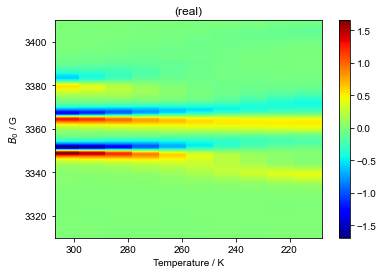

In [45]:
d = d["harmonic", 0][
    "phase", 0
]  # select only the "standard" EPR -- ignore the higher harmonics.  Make sure you can parse this!
d.pcolor()
ax=plt.gca()
ax.invert_xaxis()
#d.pcolor().invert_xaxis()
#xlim(d.shape[1],0)
#plt.gca().invert_xaxis()
#d.pcolor.invert_xaxis()


From this, I learn that
it's easiest to show the 1D plots above and below the transition

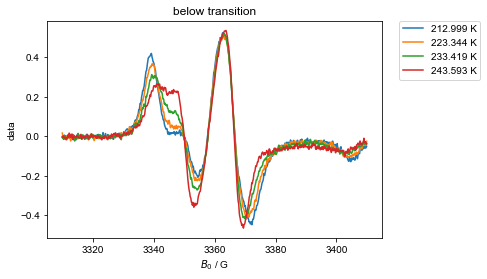

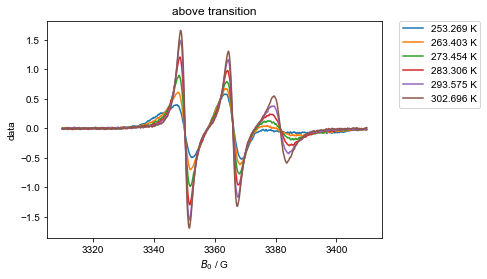

In [5]:
for this_label, temp_range in [
    ("below transition", (None, 247.8)),
    ("above transition", (248, None)),
]:
    this_d = d["Temperature":temp_range]
    figure() # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d.shape["Temperature"]):
        this_temp = this_d.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d["Temperature", temp_ithis_dx], label=f"{this_temp} K")
    fancy_legend()

What if I wanted to pull the max and min to calculate the correlation time? How would I do that?

Start by slicing out the left peak -- note that the way I loaded pyspecdata at the top, inspecting an nddata just gives me a plot:

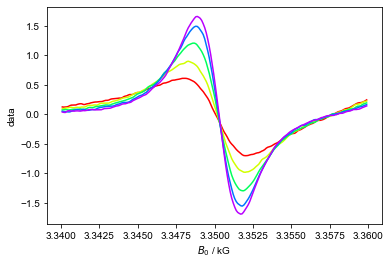

In [6]:
d["Temperature":(258,None)]['$B_0$':(3340,3360)]

Here, I'm going to take the peak I just sliced, and determine its linewidth.  This is a simple example, but contains all the programming that I would need to, e.g. determine the correlation time or the hyperfine coupling using the traditional methods that look at the peak heights and linewidths:

the linewidth at 263.403 K is 4.003906260019448 G
the peak to peak amplitude at 263.403 K is 1.3096183341171965
the linewidth at 273.454 K is 3.7109375092863957 G
the peak to peak amplitude at 273.454 K is 1.8796513974533164
the linewidth at 283.306 K is 3.2226562580644895 G
the peak to peak amplitude at 283.306 K is 2.4990341346153846
the linewidth at 293.575 K is 3.027343757575636 G
the peak to peak amplitude at 293.575 K is 3.0440692725752507
the linewidth at 302.696 K is 2.8320312570867827 G
the peak to peak amplitude at 302.696 K is 3.346003829170151


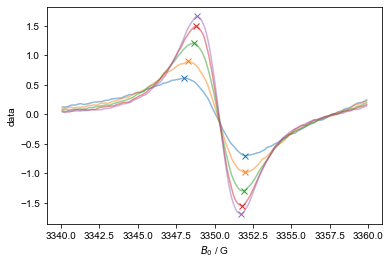

In [7]:
this_d = d["Temperature":(258,None)]['$B_0$':(3340,3360)]
default_color_cycle = cycle(rcParams['axes.prop_cycle'].by_key()['color'])
for j in range(this_d.shape["Temperature"]):
    c = next(default_color_cycle)
    plot(this_d['Temperature',j],alpha=0.5,c=c)
    field_at_max = this_d['Temperature',j].argmax().item()
    plot(field_at_max,this_d['Temperature',j]['$B_0$':field_at_max].item(),'x',c=c)
    field_at_min = this_d['Temperature',j].argmin()['$B_0$'] # it's a pyspecdata error that this isn't the same as argmax
    plot(field_at_min,this_d['Temperature',j]['$B_0$':field_at_min].item(),'x',c=c)
    print("the linewidth at",this_d['Temperature'][j],"K is",field_at_min-field_at_max,"G")
    print("the peak to peak amplitude at",this_d['Temperature'][j],"K is",(
        this_d['Temperature',j]['$B_0$':field_at_max].item()
        - this_d['Temperature',j]['$B_0$':field_at_min].item()))